# Practical 3: Multiple Linear Regression (MSE, RMSE, R²)

**Aim:** Build a multiple linear regression model on a real dataset and judge it with MSE, RMSE and R².

**Dataset:** Diabetes (442 patients, 10 features such as bmi, bp, s1 to s6). The target is a number showing how much the disease progressed after one year. Built into scikit-learn.

**Steps:** 1) Load and explore  2) Split  3) Train  4) Predict and measure errors  5) Graphs

## Step 1: Load and explore

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data = load_diabetes(as_frame=True)
df = data.frame
df = df.rename(columns={"target": "progression"})
print(df.shape)
df.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


0 missing values


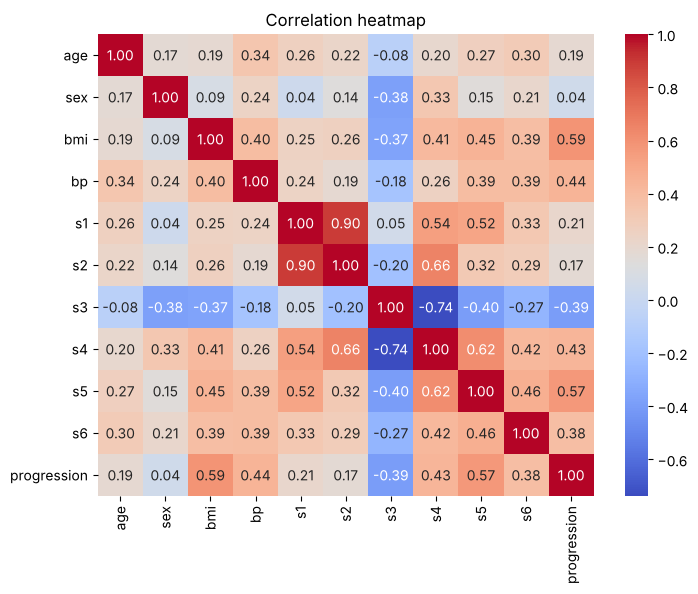

In [2]:
print(df.isnull().sum().sum(), "missing values")

# Correlation heatmap: how strongly do the columns move together?
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

**How to read:** each cell is a correlation from -1 to +1 (red = move together, blue = move opposite). Look at the last row: `bmi` and `s5` are most related to `progression`. Also `s1` and `s2` are strongly related to each other: this is **multicollinearity**.

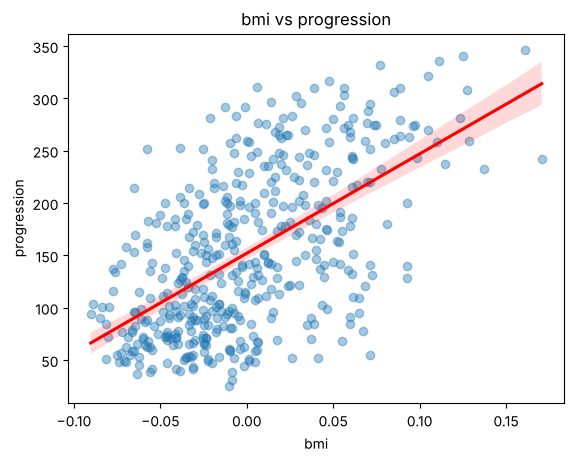

In [3]:
# One feature vs the target with its best-fit line
sns.regplot(x=df["bmi"], y=df["progression"], scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("bmi vs progression")
plt.show()

**How to read:** each dot is a patient. The red line goes up, so higher bmi goes with higher progression. The dots are spread around the line, so one feature alone is not enough: that is why we use all 10.

## Step 2: Split into train and test

In [4]:
X = df.drop(columns="progression")   # 10 input features
y = df["progression"]                # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (353, 10)  Test: (89, 10)


## Step 3: Train the model
The model learns this equation: `progression = b0 + b1*age + b2*sex + ... + b10*s6`

Intercept (b0): 151.35
age     37.90
sex   -241.96
bmi    542.43
bp     347.70
s1    -931.49
s2     518.06
s3     163.42
s4     275.32
s5     736.20
s6      48.67
dtype: float64


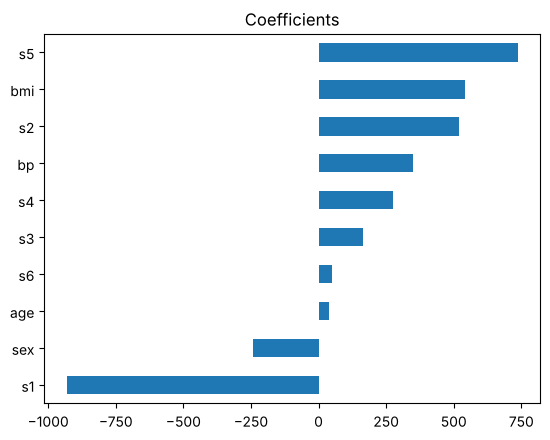

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept (b0):", round(model.intercept_, 2))
coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.round(2))

coefficients.sort_values().plot(kind="barh")
plt.title("Coefficients")
plt.show()

**How to read:** a coefficient says how much the prediction changes when that feature goes up by 1 (others fixed). Big positive: `s5`, `bmi`, `bp`. The huge opposite values for `s1` and `s2` are caused by multicollinearity (they are almost copies of each other), not because `s1` really lowers the disease.

## Step 4: Predict and measure the errors

- **MSE** = average of (actual - predicted)². **RMSE** = square root of MSE (same unit as the target).
- **R²** = share of the variation the model explains (1 is perfect, 0 is as bad as guessing the average).

In [6]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAE :", round(mae, 2))
print("R2  :", round(r2, 3))

# Compare with the training score to check for overfitting
print("Train R2:", round(r2_score(y_train, model.predict(X_train)), 3))

MSE : 2900.19
RMSE: 53.85
MAE : 42.79
R2  : 0.453
Train R2: 0.528


**Meaning:** R² is about 0.45, so the model explains roughly half of the variation: a moderate result. The predictions are off by about 54 on average (RMSE). Train and test R² are close, so there is no overfitting; the model is just limited.

## Step 5: Graphs

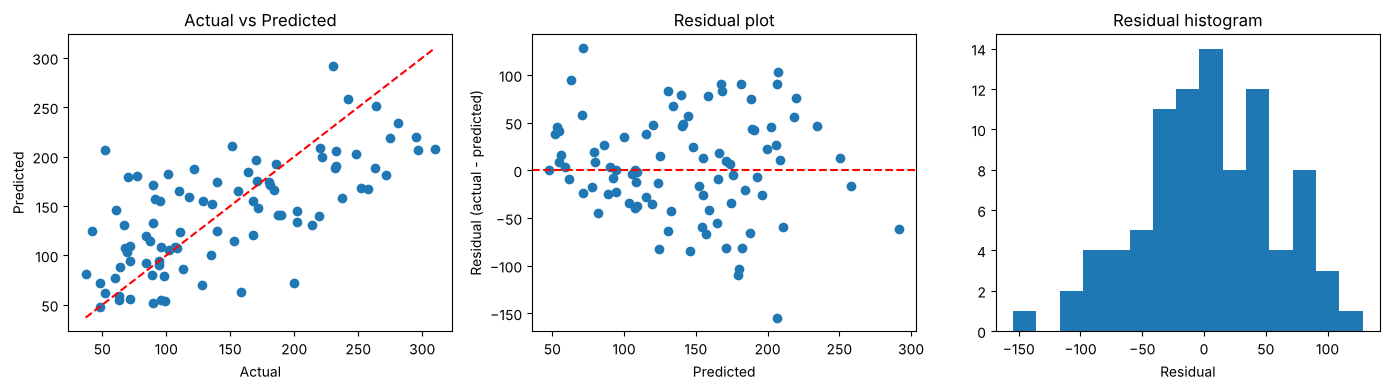

In [7]:
plt.figure(figsize=(14, 4))

# 1. Actual vs predicted
plt.subplot(1, 3, 1)
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")

# 2. Residuals (errors) vs predicted
residuals = y_test - y_pred
plt.subplot(1, 3, 2)
plt.scatter(y_pred, residuals)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual plot")

# 3. Histogram of residuals
plt.subplot(1, 3, 3)
plt.hist(residuals, bins=15)
plt.xlabel("Residual")
plt.title("Residual histogram")

plt.tight_layout()
plt.show()

**How to read:**
1. **Actual vs Predicted:** the red dashed line is perfect prediction. Dots close to it are good. Our dots are widely spread, matching the moderate R².
2. **Residual plot:** a good plot is a random cloud around 0 with no pattern. A curve or a funnel shape would mean the linear model is missing something.
3. **Histogram:** should look like a bell centred at 0 (errors are mostly small and balanced).

## Conclusion
A multiple linear regression on 10 features gave R² of about 0.45 and RMSE of about 54: it explains about half of the variation. Train and test scores are similar (no overfitting). `s1` and `s2` are strongly correlated (multicollinearity), which Ridge or Lasso (Practical 5) can handle.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is linear regression?**
A supervised algorithm that models a continuous target as a linear combination of the input features by fitting a straight line (or hyperplane).

**Q2. What is multiple linear regression? Write the equation.**
Regression with two or more features: $y = b_0 + b_1x_1 + b_2x_2 + \dots + b_nx_n + \varepsilon$, where $b_0$ is the intercept and $b_1 \dots b_n$ are coefficients.

**Q3. Difference between simple and multiple linear regression?**
Simple has one input feature; multiple has two or more.

**Q4. How are the coefficients found?**
By Ordinary Least Squares, which minimises the sum of squared residuals. Closed form: $\beta = (X^TX)^{-1}X^Ty$. Gradient descent can also be used.

**Q5. What does a coefficient mean?**
The expected change in the target for a one-unit increase in that feature, with all other features held constant.

**Q6. What is the intercept?**
The predicted value when all features are zero (here, since the features are centred, it is the average target).

**Q7. Explain MSE, RMSE and MAE.**
MSE is the average of squared errors (penalises big errors, units squared). RMSE is its square root (same units as target, easy to interpret). MAE is the average absolute error (less sensitive to outliers).

**Q8. Explain R².**
The proportion of variance in the target explained by the model. 1 is perfect, 0 means no better than predicting the mean, and it can be negative for a very bad model.

**Q9. What is adjusted R² and why use it?**
R² never decreases when you add features, even useless ones. Adjusted R² penalises extra features, so it increases only if a new feature really helps.

**Q10. What are the assumptions of linear regression?**
Linearity, independence of errors, homoscedasticity (constant error variance), normally distributed errors, and no multicollinearity. Memory aid: **LINE** (Linearity, Independence, Normality, Equal variance).

**Q11. What is multicollinearity and how do you detect it?**
When features are highly correlated with each other, making coefficients unstable. Detect with the correlation matrix or VIF (above 5 or 10 is a concern). Fix by dropping features, PCA, or Ridge regression.

**Q12. What is the difference between RMSE and R²?**
RMSE is an absolute error in the target's units (lower is better). R² is a relative, unitless measure of fit (higher is better).

**Q13. Why do we use squared error and not absolute error?**
Squared error is smooth and differentiable, gives a unique closed-form solution, and penalises large errors more.

**Q14. Is linear regression sensitive to outliers?**
Yes, because squared errors give outliers a large pull on the line.

**Q15. Is scaling needed for linear regression?**
Not for the OLS solution itself, but it helps for gradient descent, regularised models and for comparing coefficient sizes.

**Q16. How do you improve a weak R²?**
Add or engineer features, handle outliers, use polynomial features, use regularisation, or try non-linear models such as Random Forest.

**Q17. What is heteroscedasticity?**
When the variance of the errors changes across the predicted values (funnel shape in the residual plot). It violates the equal-variance assumption.

**Q18. What is the difference between regression and classification?**
Regression predicts a continuous number; classification predicts a category.

**Q19. What are the problems if train R² is high but test R² is low?**
Overfitting: the model memorised the training data. Remedies: regularisation, fewer features, more data, cross-validation.

**Q20. What is the "best fit line"?**
The line that minimises the sum of squared vertical distances between the points and the line.

**Q21. Can R² be negative?**
Yes, on test data, if the model predicts worse than simply using the mean of the target.

**Q22. What is the normal equation and when is it a bad idea?**
$\beta = (X^TX)^{-1}X^Ty$. It is slow for a very large number of features (matrix inversion is $O(p^3)$) and fails if $X^TX$ is singular (perfect multicollinearity).

## B. Questions about the graphs

**G1. What does the Actual vs Predicted plot show?**
Each dot is one test sample. The red dashed line is perfect prediction (y = x). Points near it are accurate; wide scatter means large errors.

**G2. Why is the cloud flatter than the red line?**
The model shrinks predictions toward the mean: it over-predicts low values and under-predicts high values. This is common when R² is moderate.

**G3. What does the residual plot show and what should a good one look like?**
Residual = actual minus predicted. A good plot is a random cloud around zero with constant spread and no pattern. A curve means non-linearity; a funnel shape means heteroscedasticity. Either means the linear model is not ideal.

**G4. What does the residual histogram tell you?**
Whether residuals are approximately normal. A bell shape centred at zero supports the normality assumption; a skewed or long-tailed shape shows some large errors.

**G5. What does the correlation heatmap tell you?**
The pairwise correlation between variables (-1 to +1). A strong correlation between a feature and the target means a good predictor. A strong correlation between two features signals multicollinearity.

**G6. What does the single-feature regression plot show?**
A scatter of one feature versus the target with the best-fit line. The slope indicates the direction and strength of the relationship.

**G7. What does the coefficient bar chart show?**
The size and sign of each coefficient: red bars increase the target, blue bars decrease it. Because features are on the same scale here, bar length compares importance (but unstable if features are collinear).

## C. Code questions

**C1. What do `fit()` and `predict()` do?**
`fit` learns the coefficients from training data; `predict` computes $\hat{y}$ for new data using them.

**C2. Why do we evaluate on the test set and not the training set?**
Training error is optimistic; the test set shows performance on unseen data.

**C3. What does `random_state=42` do?**
Makes the random split reproducible.

**C4. What does `model.coef_` and `model.intercept_` return?**
Coefficients (one per feature) and the intercept $b_0$.

**C5. Why `np.sqrt(mse)` for RMSE?**
RMSE is defined as the square root of MSE, which returns the error to the target's units.